# Comparaison du comptage de mots

On compare quatre méthodes sur les mêmes fichiers : Python, une simulation MapReduce, Hadoop et PySpark. On vérifie les comptages et on mesure les temps d’exécution.

On commence par générer un fichier de 500 mots.

In [1]:
import random
from pathlib import Path

class Loot:
  def __init__(self, kv_probs: dict):
    self.__kv_probs = kv_probs
    self.__total = sum(kv_probs.values())
    self.__gen = random.Random()

  def next(self):
    chosen = self.__gen.randint(1, self.__total)
    acc = 0

    for item, weight in self.__kv_probs.items():
      acc += weight
      if chosen <= acc:
        return item

animal_weights = {
    "souris": 50,
    "pigeon": 40,
    "écureuil": 35,
    "chat": 30,
    "chien": 25,
    "lapin": 20,
    "renard": 15,
    "chouette": 12,
    "cerf": 10,
    "sanglier": 8,
    "loup": 5,
    "aigle": 4,
    "ours": 3,
    "lynx": 2,
    "panthère": 1,
    "phénix": 1,
}

animal_choicer = Loot(animal_weights)

file = Path("mots.txt")

with open(file, "w", encoding="utf-8") as f:
    for _ in range(500):
        f.write(animal_choicer.next() + "\n")

print("File created :", file.resolve())
print("File content :")
print(file.read_text(encoding="utf-8"))

File created : /home/dada/Documents/Cours/BigData/mots.txt
File content :
souris
souris
renard
pigeon
lapin
chien
chouette
écureuil
chat
renard
souris
pigeon
sanglier
chien
chouette
pigeon
chien
cerf
écureuil
souris
chouette
renard
écureuil
lapin
écureuil
cerf
pigeon
chouette
écureuil
pigeon
chouette
pigeon
chat
lapin
souris
souris
pigeon
sanglier
souris
souris
panthère
chat
souris
souris
lapin
chien
renard
chat
souris
écureuil
souris
souris
ours
chat
souris
lapin
cerf
chat
souris
chien
écureuil
pigeon
chat
chien
chat
pigeon
chat
chien
souris
souris
chat
écureuil
lapin
souris
souris
pigeon
aigle
écureuil
chouette
souris
chat
lapin
chouette
chat
pigeon
chien
chien
ours
souris
cerf
pigeon
pigeon
lapin
écureuil
renard
souris
souris
souris
cerf
chien
pigeon
souris
chouette
lapin
chat
écureuil
chat
écureuil
loup
chat
chat
lapin
chouette
écureuil
écureuil
lapin
chat
pigeon
loup
souris
pigeon
renard
écureuil
souris
souris
cerf
souris
écureuil
souris
chien
chouette
pigeon
pigeon
chouette
écure

Cette fonction mesure le temps d’exécution de chaque méthode.

In [2]:
from time import perf_counter

def execute_with_performances(function) :
    s = perf_counter()
    r = function()
    t = perf_counter() - s
    return r, t


On compte les mots avec un dictionnaire Python, en lisant le fichier ligne par ligne.

In [3]:
from pathlib import Path

def count_words_python(file_path):
    word_counts = {}

    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            for word in line.split():
                word_counts[word] = word_counts.get(word, 0) + 1

    return word_counts

python_results, python_time = execute_with_performances(
    lambda: count_words_python("mots.txt")
)

print("Python Word Counter")
print("Results:", python_results)
print(f"Execution time: {python_time:.6f} seconds")

Python Word Counter
Results: {'souris': 97, 'renard': 30, 'pigeon': 79, 'lapin': 33, 'chien': 51, 'chouette': 25, 'écureuil': 60, 'chat': 68, 'sanglier': 11, 'cerf': 22, 'panthère': 2, 'ours': 8, 'aigle': 3, 'loup': 6, 'phénix': 1, 'lynx': 4}
Execution time: 0.000300 seconds


On reproduit les étapes Map, Shuffle et Reduce par lots de 10 000 lignes pour limiter la mémoire.

In [4]:

def map_words(lines):
    return [(word, 1) for line in lines for word in line.split()]

def shuffle_words(mapped_data):
    grouped_data = {}

    for word, count in mapped_data:
        grouped_data.setdefault(word, []).append(count)

    return grouped_data

def reduce_words(grouped_data):
    return {
        word: sum(counts)
        for word, counts in grouped_data.items()
    }

def count_words_mapreduce(file_path):
    from itertools import islice
    totals = {}
    with open(file_path, "r", encoding="utf-8") as file:
        while batch := list(islice(file, 10_000)):
            mapped_data = map_words(batch)
            reduced = reduce_words(shuffle_words(mapped_data))
            for word, count in reduced.items():
                totals[word] = totals.get(word, 0) + count
    return totals

mapreduce_results, mapreduce_time = execute_with_performances(
    lambda: count_words_mapreduce("mots.txt")
)

print("Pseudo-MapReduce Word Counter")
print("Results:", mapreduce_results)
print(f"Execution time: {mapreduce_time:.6f} seconds")

Pseudo-MapReduce Word Counter
Results: {'souris': 97, 'renard': 30, 'pigeon': 79, 'lapin': 33, 'chien': 51, 'chouette': 25, 'écureuil': 60, 'chat': 68, 'sanglier': 11, 'cerf': 22, 'panthère': 2, 'ours': 8, 'aigle': 3, 'loup': 6, 'phénix': 1, 'lynx': 4}
Execution time: 0.000604 seconds


Le mapper associe chaque mot à la valeur 1.

In [5]:

%%writefile mapper.py
import sys

for line in sys.stdin:
    for word in line.strip().split():
        print(f"{word}\t1")


Overwriting mapper.py


Le reducer additionne les valeurs pour obtenir le nombre d’occurrences de chaque mot.

In [6]:

%%writefile reducer.py
import sys

current_word = None
current_count = 0

for line in sys.stdin:
    word, count = line.strip().split("\t", 1)
    count = int(count)

    if word == current_word:
        current_count += count
    else:
        if current_word is not None:
            print(f"{current_word}\t{current_count}")

        current_word = word
        current_count = count

if current_word is not None:
    print(f"{current_word}\t{current_count}")


Overwriting reducer.py


On configure Hadoop et on lance le comptage en mode local.

In [7]:

import os
import subprocess
import shutil
from pathlib import Path

def run_hadoop(command, **kwargs):
    kwargs.setdefault("capture_output", True)
    kwargs.setdefault("text", True)
    kwargs.setdefault("timeout", 1800)
    try:
        return subprocess.run(command, **kwargs)
    except subprocess.CalledProcessError as error:
        print(error.stdout or "", flush=True)
        print(error.stderr or "", flush=True)
        raise
    except subprocess.TimeoutExpired:
        print("La commande Hadoop a dépassé le délai de 1800 secondes.", flush=True)
        raise

hadoop_home = Path("/home/dada/Documents/Cours/BigData/hadoop-3.5.0")
if not (hadoop_home / "bin/hadoop").is_file():
    raise FileNotFoundError(f"Hadoop introuvable dans {hadoop_home}")

java = shutil.which("java")
if java is None:
    raise RuntimeError("Java est introuvable dans le PATH")

os.environ["HADOOP_HOME"] = str(hadoop_home)
os.environ["JAVA_HOME"] = str(Path(java).resolve().parent.parent)
os.environ["PATH"] = f"{hadoop_home / 'bin'}:{os.environ['PATH']}"

print(run_hadoop(["hadoop", "version"], check=True).stdout, flush=True)

def count_words_hadoop(file_path):
    streaming_jars = list(Path(os.environ["HADOOP_HOME"]).glob(
        "share/hadoop/tools/lib/hadoop-streaming*.jar"
    ))

    if not streaming_jars:
        raise FileNotFoundError("Hadoop Streaming JAR not found")

    streaming_jar = str(streaming_jars[0])
    temporary_dir = Path("benchmark_data/hadoop_tmp").resolve()
    temporary_dir.mkdir(parents=True, exist_ok=True)
    input_path = str(Path("wordcount/input").resolve())
    output_path = str(Path("wordcount/output").resolve())

    run_hadoop(
        ["hdfs", "dfs", "-mkdir", "-p", input_path],
        check=True
    )

    run_hadoop(
        ["hdfs", "dfs", "-put", "-f", file_path, input_path],
        check=True
    )

    run_hadoop(
        ["hdfs", "dfs", "-rm", "-r", "-f", output_path],
        check=True,
        capture_output=True
    )

    run_hadoop(
        [
            "hadoop", "jar", streaming_jar,
            "-D", f"hadoop.tmp.dir={temporary_dir}",
            "-files", "mapper.py,reducer.py",
            "-input", f"{input_path}/{Path(file_path).name}",
            "-output", output_path,
            "-mapper", "python3 mapper.py",
            "-reducer", "python3 reducer.py"
        ],
        check=True
    )

    result = run_hadoop(
        ["hdfs", "dfs", "-cat", f"{output_path}/part-*"],
        capture_output=True,
        text=True,
        check=True
    )

    return {
        word: int(count)
        for word, count in (
            line.split("\t") for line in result.stdout.splitlines()
        )
    }

print("Comptage Hadoop en cours…", flush=True)
hadoop_results, hadoop_time = execute_with_performances(
    lambda: count_words_hadoop("mots.txt")
)

print("Hadoop MapReduce Word Counter")
print("Results:", hadoop_results)
print(f"Execution time: {hadoop_time:.6f} seconds")


Hadoop 3.5.0
Source code repository https://github.com/apache/hadoop.git -r dbcc7cd797100e6b32cd84f85b53a5193a5f9af0
Compiled by cnauroth on 2026-03-24T16:56Z
Compiled on platform linux-x86_64
Compiled with protoc 3.25.5
From source with checksum 64582ed0a62a169c39a19c734a8f33b5
This command was run using /home/dada/Documents/Cours/BigData/hadoop-3.5.0/share/hadoop/common/hadoop-common-3.5.0.jar

Comptage Hadoop en cours…
Hadoop MapReduce Word Counter
Results: {'aigle': 3, 'cerf': 22, 'chat': 68, 'chien': 51, 'chouette': 25, 'lapin': 33, 'loup': 6, 'lynx': 4, 'ours': 8, 'panthère': 2, 'phénix': 1, 'pigeon': 79, 'renard': 30, 'sanglier': 11, 'souris': 97, 'écureuil': 60}
Execution time: 4.372120 seconds


## Comptage avec PySpark

Cette cellule installe PySpark dans l’environnement du notebook.

In [ ]:
%pip install "pyspark>=4.0,<5"

On lance Spark avec deux threads locaux et on compte les mots. La session est réutilisée ; son démarrage est exclu du temps mesuré.

In [9]:
import sys
from operator import add
from pyspark.sql import SparkSession

for java_home in [Path("/usr/lib/jvm/java-21-openjdk"), Path("/usr/lib/jvm/java-17-openjdk")]:
    if (java_home / "bin/java").is_file():
        os.environ["JAVA_HOME"] = str(java_home)
        break
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
spark_tmp = Path("benchmark_data/spark_tmp").resolve()
spark_tmp.mkdir(parents=True, exist_ok=True)
spark = (SparkSession.builder
         .master("local[2]")
         .appName("ComptageMots")
         .config("spark.ui.enabled", "false")
         .config("spark.driver.host", "127.0.0.1")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.local.dir", str(spark_tmp))
         .config("spark.pyspark.python", sys.executable)
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Version Spark :", spark.version)

def count_words_spark(file_path):
    counts = (spark.sparkContext.textFile(Path(file_path).resolve().as_uri())
              .flatMap(lambda line: line.split())
              .map(lambda word: (word, 1))
              .reduceByKey(add))
    return dict(counts.collect())

spark_results, spark_time = execute_with_performances(lambda: count_words_spark("mots.txt"))
assert spark_results == python_results == mapreduce_results == hadoop_results
print("PySpark Word Counter")
print("Results:", spark_results)
print(f"Execution time: {spark_time:.6f} seconds")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/dada/Documents/Cours/BigData/venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/13 17:04:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/13 17:04:06 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Version Spark : 4.2.0


[Stage 0:>                                                          (0 + 2) / 2]

PySpark Word Counter
Results: {'souris': 97, 'lapin': 33, 'écureuil': 60, 'cerf': 22, 'loup': 6, 'phénix': 1, 'renard': 30, 'pigeon': 79, 'chien': 51, 'chouette': 25, 'chat': 68, 'sanglier': 11, 'panthère': 2, 'ours': 8, 'aigle': 3, 'lynx': 4}
Execution time: 1.351616 seconds


On vérifie que les quatre méthodes donnent le même résultat et on compare leurs temps.

In [10]:

import pandas as pd

assert python_results == mapreduce_results == hadoop_results == spark_results

comparison = pd.DataFrame({
    "Method": ["Plain Python", "Pseudo-MapReduce", "Hadoop MapReduce", "PySpark local"],
    "Execution Time (s)": [python_time, mapreduce_time, hadoop_time, spark_time],
})

display(comparison)


,Method,Execution Time (s)
0,Plain Python,0.000300
1,Pseudo-MapReduce,0.000604
2,Hadoop MapReduce,4.372120
3,PySpark local,1.351616


## Expérience m × N

On répète un même fichier de **100 lignes** pour **m = 10, 500, 10 000, 500 000 et 1 000 000**. Cela donne des fichiers de 1 000 à 100 millions de lignes.

In [11]:
from collections import Counter

N = 100
M_VALUES = [10, 500, 10_000, 500_000, 1_000_000]
benchmark_dir = Path("benchmark_data")
benchmark_dir.mkdir(exist_ok=True)
rng = random.Random(42)
base_words = rng.choices(list(animal_weights), weights=list(animal_weights.values()), k=N)
base_counts = Counter(base_words)
base_block = ("\n".join(base_words) + "\n").encode("utf-8")
(benchmark_dir / "base_100.txt").write_bytes(base_block)
benchmark_files = {}
for m in M_VALUES:
    path = benchmark_dir / f"mots_m{m}_N{N}.txt"
    chunk_repeats = 1_000
    with path.open("wb") as file:
        for _ in range(m // chunk_repeats):
            file.write(base_block * chunk_repeats)
        file.write(base_block * (m % chunk_repeats))
    assert path.stat().st_size == len(base_block) * m
    benchmark_files[m] = path
    print(f"m={m:,} : {m * N:,} lignes, {path.stat().st_size / 1_000_000:.3f} Mo")

m=10 : 1,000 lignes, 0.007 Mo
m=500 : 50,000 lignes, 0.347 Mo
m=10,000 : 1,000,000 lignes, 6.950 Mo
m=500,000 : 50,000,000 lignes, 347.500 Mo
m=1,000,000 : 100,000,000 lignes, 695.000 Mo


On teste les quatre méthodes sur chaque taille et on vérifie les résultats. Le tableau présente les temps en secondes. Les mesures déjà enregistrées sont conservées.

Chaque cas est mesuré une seule fois. Pour Hadoop, les quatre premiers tests utilisent des temporaires en mémoire, le dernier sur disque.

In [12]:
import gc

methods = {
    "Python simple": count_words_python,
    "Pseudo-MapReduce": count_words_mapreduce,
    "Hadoop local": count_words_hadoop,
    "PySpark local": count_words_spark,
}
results_path = Path("benchmark_resultats.csv")
comparison_table = (
    pd.read_csv(results_path, index_col="Nombre de lignes")
    if results_path.exists() else pd.DataFrame()
).reindex(index=[m * N for m in M_VALUES], columns=list(methods))
comparison_table.index.name = "Nombre de lignes"

for m, path in benchmark_files.items():
    lines = m * N
    expected = {word: count * m for word, count in base_counts.items()}
    for name, function in methods.items():
        if pd.notna(comparison_table.loc[lines, name]):
            continue
        print(f"{lines:,} lignes — {name} en cours…", flush=True)
        gc.collect()
        result, elapsed = execute_with_performances(lambda: function(str(path)))
        assert result == expected, f"Comptage incorrect : {name}, m={m}"
        comparison_table.loc[lines, name] = elapsed
        comparison_table.to_csv(results_path)
        print(f"Terminé en {elapsed:.6f} s.", flush=True)
display(comparison_table.round(6))


,Python simple,Pseudo-MapReduce,Hadoop local,PySpark local
Nombre de lignes,,,,
1000,0.000260,0.000383,4.524015,0.653779
50000,0.012125,0.010657,4.516414,0.227864
1000000,0.193218,0.201008,5.525915,0.637199
50000000,9.377103,11.062664,94.066829,24.810878
100000000,30.221487,22.187442,185.028588,50.837212


Le graphique montre l’évolution des temps selon la taille du fichier. Les axes logarithmiques permettent de comparer toutes les tailles.

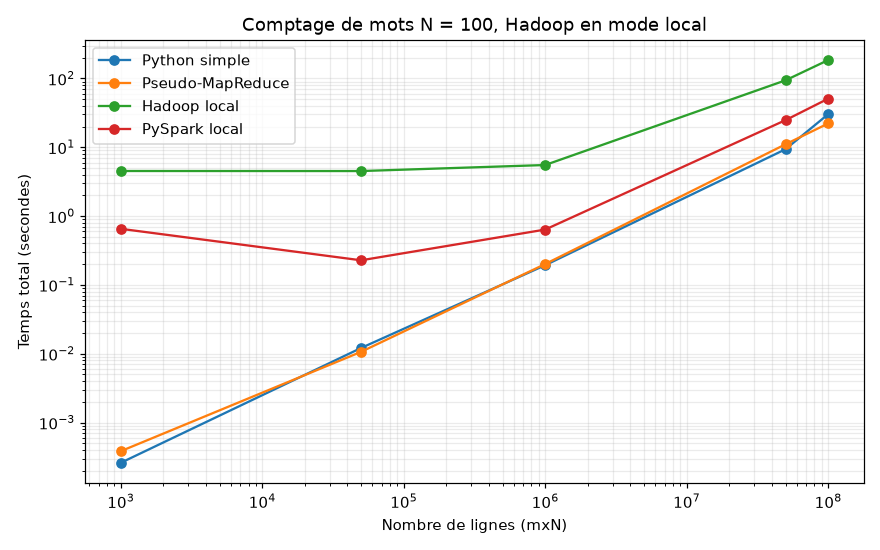

In [13]:
import matplotlib.pyplot as plt

benchmark_table = comparison_table
fig, ax = plt.subplots(figsize=(8, 5))
for name in methods:
    ax.plot(benchmark_table.index, benchmark_table[name], marker="o", label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Nombre de lignes (mxN)")
ax.set_ylabel("Temps total (secondes)")
ax.set_title("Comptage de mots N = 100, Hadoop en mode local")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("benchmark_performances.png", dpi=160)
display(fig)
plt.close(fig)

On compare les temps des quatre méthodes sur le plus gros fichier.

In [14]:
from IPython.display import Markdown

largest = comparison_table.loc[max(M_VALUES) * N]
text = f"Sur **{max(M_VALUES) * N:,} lignes**, Python prend **{largest['Python simple']:.2f} s**, "
text += f"la simulation MapReduce **{largest['Pseudo-MapReduce']:.2f} s**, Spark **{largest['PySpark local']:.2f} s** "
text += f"et Hadoop **{largest['Hadoop local']:.2f} s**. Les quatre méthodes donnent les mêmes comptages."
display(Markdown(text))


Sur **100,000,000 lignes**, Python prend **30.22 s**, la simulation MapReduce **22.19 s**, Spark **50.84 s** et Hadoop **185.03 s**. Les quatre méthodes donnent les mêmes comptages.

On arrête la session Spark une fois les tests terminés.

In [15]:
spark.stop()

## Conclusion

Les quatre méthodes donnent les mêmes comptages. Dans ces tests, les versions Python sont les plus rapides. Spark est plus rapide que Hadoop, mais reste plus lent que Python. Ces tests sont faits en local et ne représentent pas les performances d’un cluster.